# ACDC Cardiac MRI Classification

**CMPS 261 - Machine Learning Project**

This project aims to classify patients into five cardiac diagnostic groups using the ACDC cardiac MRI dataset. We will construct features from the available MRI data and segmentation masks, then train and evaluate a classical machine learning model.

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [12]:
data_path = "ACDC/database"

patients = []

for folder in ["training", "testing"]:
    folder_path = os.path.join(data_path, folder)

    for patient in sorted(os.listdir(folder_path)):
        if not patient.startswith("patient"):
            continue

        info_path = os.path.join(folder_path, patient, "Info.cfg")

        info = {}

        with open(info_path, "r") as file:
            for line in file:
                key, value = line.strip().split(":")
                info[key.strip()] = value.strip()

        info["Patient"] = patient
        info["Split"] = folder
        patients.append(info)

df = pd.DataFrame(patients)

print(df.shape)
df.head()

(150, 8)


,ED,ES,Group,Height,NbFrame,Weight,Patient,Split
0,1,12,DCM,184.0,30,95.0,patient001,training
1,1,12,DCM,160.0,30,70.0,patient002,training
2,1,15,DCM,165.0,30,77.0,patient003,training
3,1,15,DCM,159.0,28,46.0,patient004,training
4,1,13,DCM,165.0,30,77.0,patient005,training


### Class Distribution

We check the number of patients in each diagnostic group to see if the dataset is balanced.

In [13]:
print(df.groupby(["Split", "Group"]).size())

Split     Group
testing   DCM      10
          HCM      10
          MINF     10
          NOR      10
          RV       10
training  DCM      20
          HCM      20
          MINF     20
          NOR      20
          RV       20
dtype: int64


### MRI Visualization

We load an MRI volume and its segmentation mask to understand the image structure before extracting features.

Image shape: (216, 256, 10)
Mask shape: (216, 256, 10)
Mask labels: [0. 1. 2. 3.]


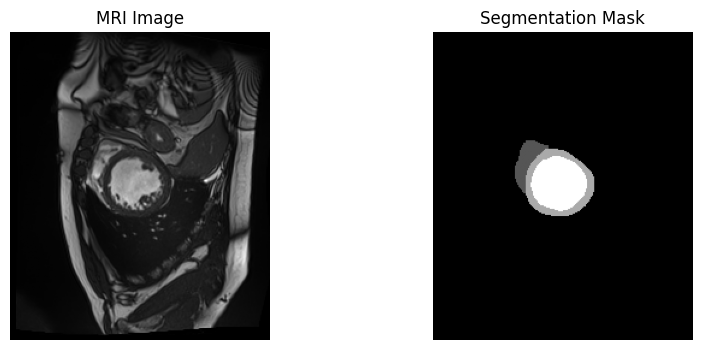

In [14]:
patient_path = os.path.join(data_path, "training", "patient001")

image = nib.load(os.path.join(patient_path, "patient001_frame01.nii.gz"))
mask = nib.load(os.path.join(patient_path, "patient001_frame01_gt.nii.gz"))

image_data = image.get_fdata()
mask_data = mask.get_fdata()

print("Image shape:", image_data.shape)
print("Mask shape:", mask_data.shape)
print("Mask labels:", np.unique(mask_data))

slice_index = image_data.shape[2] // 2

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_data[:, :, slice_index].T, cmap="gray", origin="lower")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_data[:, :, slice_index].T, cmap="gray", origin="lower")
plt.title("Segmentation Mask")
plt.axis("off")

plt.show()

### Feature Extraction

We extract cardiac volume measurements from the segmentation masks at end-diastole and end-systole. These measurements will be used as features for classification.

In [15]:
ed_mask = nib.load(os.path.join(patient_path, "patient001_frame01_gt.nii.gz"))
es_mask = nib.load(os.path.join(patient_path, "patient001_frame12_gt.nii.gz"))

ed_data = ed_mask.get_fdata()
es_data = es_mask.get_fdata()

voxel_volume = np.prod(ed_mask.header.get_zooms()[:3]) / 1000

lv_ed = np.sum(ed_data == 3) * voxel_volume
lv_es = np.sum(es_data == 3) * voxel_volume

rv_ed = np.sum(ed_data == 1) * voxel_volume
rv_es = np.sum(es_data == 1) * voxel_volume

myo_ed = np.sum(ed_data == 2) * voxel_volume

lv_ef = (lv_ed - lv_es) / lv_ed * 100
rv_ef = (rv_ed - rv_es) / rv_ed * 100

print("LV ED volume:", lv_ed)
print("LV ES volume:", lv_es)
print("RV ED volume:", rv_ed)
print("RV ES volume:", rv_es)
print("Myocardium volume:", myo_ed)
print("LV ejection fraction:", lv_ef)
print("RV ejection fraction:", rv_ef)

LV ED volume: 295.5078125
LV ES volume: 225.6103515625
RV ED volume: 139.7216796875
RV ES volume: 59.5458984375
Myocardium volume: 164.2578125
LV ejection fraction: 23.65333773959022
RV ejection fraction: 57.38249170015726


### Extracting Features for All Patients

We extract ventricular volumes, myocardial volume, and ejection fractions from the ED and ES segmentation masks for each patient.

In [16]:
features = []

for _, row in df.iterrows():
    patient = row["Patient"]
    folder = row["Split"]
    patient_path = os.path.join(data_path, folder, patient)

    ed_frame = int(row["ED"])
    es_frame = int(row["ES"])

    ed_path = os.path.join(patient_path, f"{patient}_frame{ed_frame:02d}_gt.nii.gz")
    es_path = os.path.join(patient_path, f"{patient}_frame{es_frame:02d}_gt.nii.gz")

    ed_mask = nib.load(ed_path)
    es_mask = nib.load(es_path)

    ed_data = ed_mask.get_fdata()
    es_data = es_mask.get_fdata()

    voxel_volume = np.prod(ed_mask.header.get_zooms()[:3]) / 1000

    lv_ed = np.sum(ed_data == 3) * voxel_volume
    lv_es = np.sum(es_data == 3) * voxel_volume

    rv_ed = np.sum(ed_data == 1) * voxel_volume
    rv_es = np.sum(es_data == 1) * voxel_volume

    myo_ed = np.sum(ed_data == 2) * voxel_volume

    lv_ef = (lv_ed - lv_es) / lv_ed * 100 if lv_ed > 0 else 0
    rv_ef = (rv_ed - rv_es) / rv_ed * 100 if rv_ed > 0 else 0

    features.append({
        "Patient": patient,
        "Split": folder,
        "Group": row["Group"],
        "LV_ED": lv_ed,
        "LV_ES": lv_es,
        "RV_ED": rv_ed,
        "RV_ES": rv_es,
        "MYO_ED": myo_ed,
        "LV_EF": lv_ef,
        "RV_EF": rv_ef
    })

features_df = pd.DataFrame(features)

print(features_df.shape)
features_df.head()

(150, 10)


,Patient,Split,Group,LV_ED,LV_ES,RV_ED,RV_ES,MYO_ED,LV_EF,RV_EF
0,patient001,training,DCM,295.507812,225.610352,139.721680,59.545898,164.257812,23.653338,57.382492
1,patient002,training,DCM,265.744400,188.303375,94.432068,28.823090,160.433578,29.141169,69.477435
2,patient003,training,DCM,276.708984,241.088867,192.333984,174.584961,191.845703,12.872772,9.228231
3,patient004,training,DCM,260.847092,226.472473,106.264114,84.543991,168.452454,13.178072,20.439754
4,patient005,training,DCM,290.797119,224.094727,170.463867,74.553223,201.392578,22.937776,56.264501


### Data Preprocessing

We check for missing values before preparing the data for training.

In [17]:
print(features_df.shape)
print(features_df.isnull().sum())

(150, 10)
Patient    0
Split      0
Group      0
LV_ED      0
LV_ES      0
RV_ED      0
RV_ES      0
MYO_ED     0
LV_EF      0
RV_EF      0
dtype: int64


### Train and Validation Split

We split the 100 training patients into 80% training and 20% validation using stratified sampling to preserve the class distribution. The original test set is kept separate for final evaluation.

In [18]:
feature_columns = ["LV_ED", "LV_ES", "RV_ED", "RV_ES", "MYO_ED", "LV_EF", "RV_EF"]

train_df = features_df[features_df["Split"] == "training"]
test_df = features_df[features_df["Split"] == "testing"]

X = train_df[feature_columns]
y = train_df["Group"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

print(y_train.value_counts())
print(y_val.value_counts())

Training: (80, 7)
Validation: (20, 7)
Group
RV      16
NOR     16
MINF    16
HCM     16
DCM     16
Name: count, dtype: int64
Group
MINF    4
DCM     4
NOR     4
HCM     4
RV      4
Name: count, dtype: int64


### Feature Standardization

We standardize the numerical features so they have a mean of 0 and a standard deviation of 1. The scaler is fitted only on the training data to avoid data leakage.

In [19]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)

print("Training means:", X_train_scaled.mean(axis=0))
print("Training standard deviations:", X_train_scaled.std(axis=0))

Training shape: (80, 7)
Validation shape: (20, 7)
Training means: [-7.77156117e-17  0.00000000e+00  1.99840144e-16 -4.99600361e-17
  1.11022302e-17  2.66453526e-16  6.66133815e-17]
Training standard deviations: [1. 1. 1. 1. 1. 1. 1.]


### Logistic Regression Baseline

We train a logistic regression model using the standardized features and evaluate its performance on the validation set using accuracy and macro-F1.

In [20]:
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_scaled, y_train)

y_val_pred = lr.predict(X_val_scaled)

print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation Macro-F1:", f1_score(y_val, y_val_pred, average="macro"))
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.85
Validation Macro-F1: 0.8520634920634921
              precision    recall  f1-score   support

         DCM       1.00      0.75      0.86         4
         HCM       1.00      0.75      0.86         4
        MINF       0.67      1.00      0.80         4
         NOR       0.80      1.00      0.89         4
          RV       1.00      0.75      0.86         4

    accuracy                           0.85        20
   macro avg       0.89      0.85      0.85        20
weighted avg       0.89      0.85      0.85        20



### Hyperparameter Tuning

We compare different regularization strengths for logistic regression and select the value with the highest validation macro-F1 score.

In [21]:
c_values = [0.01, 0.1, 1, 10, 100]

results = []

for c in c_values:
    model = LogisticRegression(C=c, max_iter=1000, random_state=42)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average="macro")

    results.append({
        "C": c,
        "Accuracy": accuracy,
        "Macro-F1": macro_f1
    })

results_df = pd.DataFrame(results)

results_df

,C,Accuracy,Macro-F1
0,0.01,0.95,0.949206
1,0.10,0.85,0.852063
2,1.00,0.85,0.852063
3,10.00,0.90,0.898413
4,100.00,0.90,0.898413


### Best Model Evaluation

We evaluate the selected logistic regression model on the validation set and examine its confusion matrix to identify classification errors.

Validation Accuracy: 0.95
Validation Macro-F1: 0.9492063492063492
              precision    recall  f1-score   support

         DCM       1.00      0.75      0.86         4
         HCM       1.00      1.00      1.00         4
        MINF       0.80      1.00      0.89         4
         NOR       1.00      1.00      1.00         4
          RV       1.00      1.00      1.00         4

    accuracy                           0.95        20
   macro avg       0.96      0.95      0.95        20
weighted avg       0.96      0.95      0.95        20



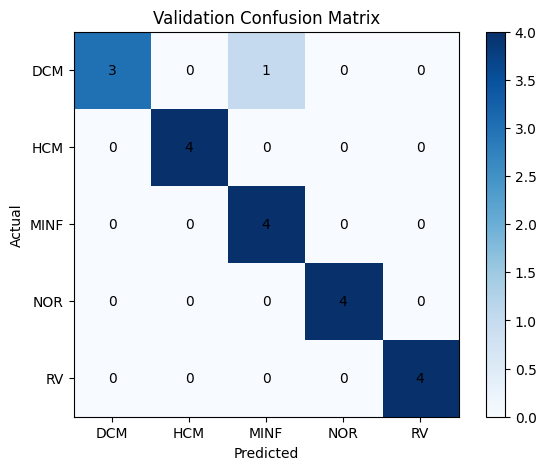

In [22]:
best_lr = LogisticRegression(C=0.01, max_iter=1000, random_state=42)

best_lr.fit(X_train_scaled, y_train)

y_val_pred = best_lr.predict(X_val_scaled)

print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation Macro-F1:", f1_score(y_val, y_val_pred, average="macro"))
print(classification_report(y_val, y_val_pred))

classes = best_lr.classes_
cm = confusion_matrix(y_val, y_val_pred, labels=classes)

plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(len(classes)), classes)
plt.yticks(range(len(classes)), classes)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Validation Confusion Matrix")

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

### Cross-Validation

We use 5-fold stratified cross-validation to check how consistently the selected model performs across different training and validation splits.

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.01, max_iter=1000, random_state=42)
)

cv_scores = cross_val_score(model, X, y, cv=cv, scoring="f1_macro")

print("Cross-validation Macro-F1:", cv_scores)
print("Mean Macro-F1:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation Macro-F1: [0.94920635 0.84920635 0.85021645 0.88888889 0.74444444]
Mean Macro-F1: 0.8563924963924963
Standard deviation: 0.06677211602479663


### Cross-Validation Tuning

We compare different regularization strengths using 5-fold stratified cross-validation to select a model that performs consistently across different splits.

In [24]:
cv_results = []

for c in c_values:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=c, max_iter=1000, random_state=42)
    )

    scores = cross_val_score(model, X, y, cv=cv, scoring="f1_macro")

    cv_results.append({
        "C": c,
        "Mean Macro-F1": scores.mean(),
        "Std Macro-F1": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,C,Mean Macro-F1,Std Macro-F1
0,0.01,0.856392,0.066772
1,0.10,0.911408,0.079397
2,1.00,0.929408,0.075120
3,10.00,0.919250,0.067982
4,100.00,0.888773,0.048815


### Final Classical Baseline

Based on cross-validation, we select logistic regression with L2 regularization and C = 1.0. We retrain the model using all 100 training patients. The test set remains separate for final evaluation.

In [25]:
best_c = cv_results_df.loc[cv_results_df["Mean Macro-F1"].idxmax(), "C"]

final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=best_c, max_iter=1000, random_state=42)
)

final_model.fit(X, y)

print("Selected C:", best_c)
print("Training patients:", len(X))
print("Best CV Macro-F1:", cv_results_df["Mean Macro-F1"].max())

Selected C: 1.0
Training patients: 100
Best CV Macro-F1: 0.9294083694083695


### Final Evaluation on the Test Set

We evaluate the Logistic Regression model on the 50 official testing patients using cardiac features extracted from expert segmentation masks. The model was trained on all 100 training patients, and the test set was not used during training or hyperparameter selection.

In [26]:
X_test = test_df[feature_columns]
y_test = test_df["Group"]

y_test_pred = final_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test Macro-F1:", f1_score(y_test, y_test_pred, average="macro"))

print()
print(classification_report(y_test, y_test_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=final_model.classes_))

Test Accuracy: 0.9
Test Macro-F1: 0.8999498746867168

              precision    recall  f1-score   support

         DCM       0.80      0.80      0.80        10
         HCM       1.00      0.90      0.95        10
        MINF       0.80      0.80      0.80        10
         NOR       0.91      1.00      0.95        10
          RV       1.00      1.00      1.00        10

    accuracy                           0.90        50
   macro avg       0.90      0.90      0.90        50
weighted avg       0.90      0.90      0.90        50

Confusion Matrix:
[[ 8  0  2  0  0]
 [ 0  9  0  1  0]
 [ 2  0  8  0  0]
 [ 0  0  0 10  0]
 [ 0  0  0  0 10]]


## Part 2: Automatic Segmentation and Classification

### Preparing MRI Data

We prepare MRI slices and their corresponding ground-truth segmentation masks. These will be used to train a Random Forest model to identify the background, right ventricle, myocardium, and left ventricle.

In [27]:
seg_images = []
seg_masks = []
seg_patients = []

for _, row in df[df["Split"] == "training"].iterrows():
    patient = row["Patient"]
    patient_path = os.path.join(data_path, "training", patient)

    for phase in ["ED", "ES"]:
        frame = int(row[phase])

        image_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}.nii.gz")
        mask_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}_gt.nii.gz")

        image = nib.load(image_path).get_fdata()
        mask = nib.load(mask_path).get_fdata()

        for i in range(image.shape[2]):
            seg_images.append(image[:, :, i])
            seg_masks.append(mask[:, :, i])
            seg_patients.append(patient)

print("Total slices:", len(seg_images))
print("First image shape:", seg_images[0].shape)
print("First mask shape:", seg_masks[0].shape)

Total slices: 1902
First image shape: (216, 256)
First mask shape: (216, 256)


### Pixel Feature Extraction

We prepare pixel intensity and position features for the segmentation model. We sample pixels from the training patients to reduce memory usage and keep the validation patients separate.

In [28]:
rng = np.random.default_rng(42)

train_patients = set(train_df.loc[X_train.index, "Patient"])
val_patients = set(train_df.loc[X_val.index, "Patient"])

X_seg_train = []
y_seg_train = []

for image, mask, patient in zip(seg_images, seg_masks, seg_patients):
    if patient not in train_patients:
        continue

    image = image.astype(np.float32)
    image = (image - image.mean()) / (image.std() + 1e-8)

    height, width = image.shape

    yy, xx = np.indices(image.shape)

    pixel_features = np.column_stack((
        image.ravel(),
        (xx / width).ravel(),
        (yy / height).ravel()
    ))

    labels = mask.ravel().astype(int)

    indices = rng.choice(len(labels), size=min(200, len(labels)), replace=False)

    X_seg_train.append(pixel_features[indices])
    y_seg_train.append(labels[indices])

X_seg_train = np.vstack(X_seg_train)
y_seg_train = np.concatenate(y_seg_train)

print("Training pixels:", X_seg_train.shape)
print("Labels:", np.unique(y_seg_train, return_counts=True))
print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))

Training pixels: (300800, 3)
Labels: (array([0, 1, 2, 3]), array([289347,   3824,   3804,   3825]))
Training patients: 80
Validation patients: 20


### Class Balancing

Most pixels belong to the background class. We balance the training data by randomly sampling an equal number of pixels from each class so the model can learn the cardiac structures more effectively.

In [29]:
class_counts = np.bincount(y_seg_train)
min_count = class_counts.min()

balanced_indices = []

for label in range(4):
    indices = np.where(y_seg_train == label)[0]
    selected = rng.choice(indices, size=min_count, replace=False)
    balanced_indices.extend(selected)

balanced_indices = np.array(balanced_indices)
rng.shuffle(balanced_indices)

X_seg_balanced = X_seg_train[balanced_indices]
y_seg_balanced = y_seg_train[balanced_indices]

print("Balanced training shape:", X_seg_balanced.shape)
print("Class counts:", np.unique(y_seg_balanced, return_counts=True))

Balanced training shape: (15216, 3)
Class counts: (array([0, 1, 2, 3]), array([3804, 3804, 3804, 3804]))


### Random Forest Segmentation

We train a Random Forest classifier to predict the segmentation label of each pixel using its intensity and position. The model predicts background, right ventricle, myocardium, or left ventricle.

In [30]:
from sklearn.ensemble import RandomForestClassifier

rf_seg = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_seg.fit(X_seg_balanced, y_seg_balanced)

print("Random Forest training completed")
print("Number of trees:", rf_seg.n_estimators)
print("Number of training pixels:", len(X_seg_balanced))

Random Forest training completed
Number of trees: 100
Number of training pixels: 15216


### Segmentation Prediction

We use the trained Random Forest to predict the segmentation mask of a validation MRI slice and compare it with the ground-truth mask.

Validation patient: patient007
Predicted labels: [0 1 2 3]


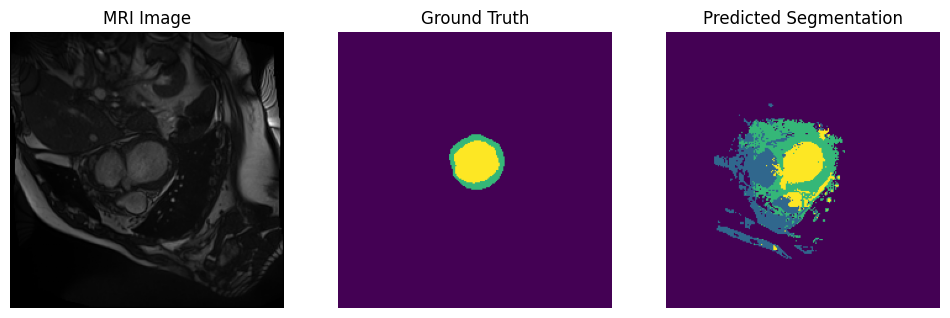

In [31]:
val_patient = sorted(val_patients)[0]

for image, mask, patient in zip(seg_images, seg_masks, seg_patients):
    if patient == val_patient and np.any(mask > 0):
        val_image = image
        val_mask = mask
        break

val_image = val_image.astype(np.float32)
val_image = (val_image - val_image.mean()) / (val_image.std() + 1e-8)

height, width = val_image.shape
yy, xx = np.indices(val_image.shape)

val_features = np.column_stack((
    val_image.ravel(),
    (xx / width).ravel(),
    (yy / height).ravel()
))

pred_mask = rf_seg.predict(val_features).reshape(height, width)

print("Validation patient:", val_patient)
print("Predicted labels:", np.unique(pred_mask))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(val_image.T, cmap="gray", origin="lower")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(val_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Predicted Segmentation")
plt.axis("off")

plt.show()

### Segmentation Evaluation

We evaluate the predicted segmentation using the Dice coefficient, which measures the overlap between predicted and ground-truth regions. We calculate Dice separately for the right ventricle, myocardium, and left ventricle.

In [32]:
dice_scores = {}

for label, name in [(1, "RV"), (2, "Myocardium"), (3, "LV")]:
    predicted = pred_mask == label
    actual = val_mask == label

    intersection = np.sum(predicted & actual)
    total = np.sum(predicted) + np.sum(actual)

    dice = 2 * intersection / total if total > 0 else 1.0
    dice_scores[name] = dice

    print(name, "Dice:", round(dice, 4))

print("Mean Dice:", round(np.mean(list(dice_scores.values())), 4))

RV Dice: 0.0
Myocardium Dice: 0.356
LV Dice: 0.7505
Mean Dice: 0.3689


### Improving Pixel Sampling

The initial segmentation model produced noisy predictions and false positives. We improve the training data by sampling pixels from each class separately, keeping more background examples while ensuring that the cardiac structures are represented.

In [33]:
X_seg_improved = []
y_seg_improved = []

rng = np.random.default_rng(42)

samples_per_class = {
    0: 500,
    1: 200,
    2: 200,
    3: 200
}

for image, mask, patient in zip(seg_images, seg_masks, seg_patients):
    if patient not in train_patients:
        continue

    image = image.astype(np.float32)
    image = (image - image.mean()) / (image.std() + 1e-8)

    height, width = image.shape
    yy, xx = np.indices(image.shape)

    pixel_features = np.column_stack((
        image.ravel(),
        (xx / width).ravel(),
        (yy / height).ravel()
    ))

    labels = mask.ravel().astype(int)

    for label in range(4):
        indices = np.where(labels == label)[0]

        if len(indices) == 0:
            continue

        count = min(samples_per_class[label], len(indices))
        selected = rng.choice(indices, size=count, replace=False)

        X_seg_improved.append(pixel_features[selected])
        y_seg_improved.append(labels[selected])

X_seg_improved = np.vstack(X_seg_improved)
y_seg_improved = np.concatenate(y_seg_improved)

print("Training pixels:", X_seg_improved.shape)
print("Class counts:", np.unique(y_seg_improved, return_counts=True))

Training pixels: (1525573, 3)
Class counts: (array([0, 1, 2, 3]), array([752000, 224566, 285384, 263623]))


### Retraining the Segmentation Model

We retrain the Random Forest using the improved pixel sampling strategy. We keep the same hyperparameters to compare its performance with the original model.

In [34]:
rf_seg_improved = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_seg_improved.fit(X_seg_improved, y_seg_improved)

print("Improved Random Forest training completed")
print("Number of training pixels:", len(X_seg_improved))

Improved Random Forest training completed
Number of training pixels: 1525573


### Comparing Segmentation Models

We compare the original and improved Random Forest models on the same validation MRI slice. We visualize their predicted masks and calculate Dice scores for each cardiac structure to determine whether the new sampling strategy improved segmentation.

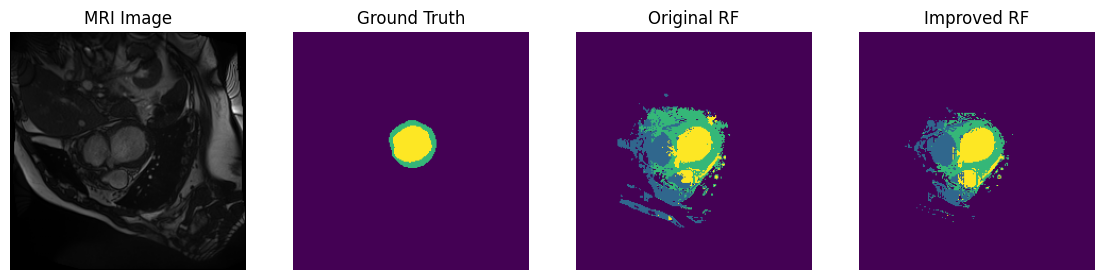

Dice Score Comparison
RV Original: 0.0 Improved: 0.0
Myocardium Original: 0.356 Improved: 0.4815
LV Original: 0.7505 Improved: 0.7547


In [35]:
pred_mask_improved = rf_seg_improved.predict(val_features).reshape(val_image.shape)

plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(val_image.T, cmap="gray", origin="lower")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(val_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(pred_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Original RF")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(pred_mask_improved.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Improved RF")
plt.axis("off")

plt.show()

print("Dice Score Comparison")

for label, name in [(1, "RV"), (2, "Myocardium"), (3, "LV")]:
    actual = val_mask == label

    original = pred_mask == label
    improved = pred_mask_improved == label

    original_total = np.sum(original) + np.sum(actual)
    improved_total = np.sum(improved) + np.sum(actual)

    original_dice = 2 * np.sum(original & actual) / original_total if original_total > 0 else 1.0
    improved_dice = 2 * np.sum(improved & actual) / improved_total if improved_total > 0 else 1.0

    print(name, "Original:", round(original_dice, 4), "Improved:", round(improved_dice, 4))

### Validation Segmentation Performance

We evaluate the improved Random Forest on all validation patients. Dice scores are calculated for the right ventricle, myocardium, and left ventricle using the predicted and ground-truth masks.

In [36]:
dice_results = []

for patient in sorted(val_patients):
    patient_images = [
        (image, mask)
        for image, mask, p in zip(seg_images, seg_masks, seg_patients)
        if p == patient
    ]

    intersections = np.zeros(3)
    predicted_counts = np.zeros(3)
    actual_counts = np.zeros(3)

    for image, mask in patient_images:
        image = image.astype(np.float32)
        image = (image - image.mean()) / (image.std() + 1e-8)

        h, w = image.shape
        yy, xx = np.indices(image.shape)

        pixel_features = np.column_stack((
            image.ravel(),
            (xx / w).ravel(),
            (yy / h).ravel()
        ))

        prediction = rf_seg_improved.predict(pixel_features).reshape(image.shape)

        for label in range(1, 4):
            predicted = prediction == label
            actual = mask == label

            intersections[label - 1] += np.sum(predicted & actual)
            predicted_counts[label - 1] += np.sum(predicted)
            actual_counts[label - 1] += np.sum(actual)

    scores = []

    for i in range(3):
        total = predicted_counts[i] + actual_counts[i]
        dice = 2 * intersections[i] / total if total > 0 else 1.0
        scores.append(dice)

    dice_results.append({
        "Patient": patient,
        "RV": scores[0],
        "Myocardium": scores[1],
        "LV": scores[2]
    })

dice_df = pd.DataFrame(dice_results)

print("Mean Dice across validation patients:")
print(dice_df[["RV", "Myocardium", "LV"]].mean().round(4))
print("Overall Mean Dice:", round(dice_df[["RV", "Myocardium", "LV"]].mean().mean(), 4))

Mean Dice across validation patients:
RV            0.3145
Myocardium    0.3284
LV            0.5415
dtype: float64
Overall Mean Dice: 0.3948


### Adding Neighborhood Features

The initial segmentation model achieved a mean Dice score of 0.3948 on the validation patients. To improve segmentation, we add local average intensity features using 3×3 and 7×7 neighborhoods. These features provide information about surrounding pixels rather than relying only on individual pixel intensity and position.

In [37]:
from scipy.ndimage import uniform_filter

X_seg_local = []
y_seg_local = []

rng = np.random.default_rng(42)

for image, mask, patient in zip(seg_images, seg_masks, seg_patients):
    if patient not in train_patients:
        continue

    image = image.astype(np.float32)
    image = (image - image.mean()) / (image.std() + 1e-8)

    h, w = image.shape
    yy, xx = np.indices(image.shape)

    avg_3 = uniform_filter(image, size=3)
    avg_7 = uniform_filter(image, size=7)

    pixel_features = np.column_stack((
        image.ravel(),
        (xx / w).ravel(),
        (yy / h).ravel(),
        avg_3.ravel(),
        avg_7.ravel()
    ))

    labels = mask.ravel().astype(int)

    for label in range(4):
        indices = np.where(labels == label)[0]

        if len(indices) == 0:
            continue

        count = min(samples_per_class[label], len(indices))
        selected = rng.choice(indices, size=count, replace=False)

        X_seg_local.append(pixel_features[selected])
        y_seg_local.append(labels[selected])

X_seg_local = np.vstack(X_seg_local)
y_seg_local = np.concatenate(y_seg_local)

print("Training shape:", X_seg_local.shape)
print("Class counts:", np.unique(y_seg_local, return_counts=True))

Training shape: (1525573, 5)
Class counts: (array([0, 1, 2, 3]), array([752000, 224566, 285384, 263623]))


### Random Forest with Neighborhood Features

We train a new Random Forest segmentation model using pixel intensity, normalized position, and local average intensity from 3×3 and 7×7 neighborhoods. We keep the same hyperparameters as the previous model to evaluate the effect of adding neighborhood features.

In [38]:
rf_seg_local = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_seg_local.fit(X_seg_local, y_seg_local)

print("Random Forest with neighborhood features trained")
print("Training pixels:", len(X_seg_local))
print("Number of features:", X_seg_local.shape[1])

Random Forest with neighborhood features trained
Training pixels: 1525573
Number of features: 5


### Evaluating Neighborhood Features

We evaluate the new segmentation model on the validation patients using Dice scores for the right ventricle, myocardium, and left ventricle. We compare the results with the previous Random Forest to determine whether neighborhood features improve segmentation.

In [39]:
dice_results_local = []

for patient in sorted(val_patients):
    intersections = np.zeros(3)
    predicted_counts = np.zeros(3)
    actual_counts = np.zeros(3)

    for image, mask, p in zip(seg_images, seg_masks, seg_patients):
        if p != patient:
            continue

        image = image.astype(np.float32)
        image = (image - image.mean()) / (image.std() + 1e-8)

        h, w = image.shape
        yy, xx = np.indices(image.shape)

        avg_3 = uniform_filter(image, size=3)
        avg_7 = uniform_filter(image, size=7)

        pixel_features = np.column_stack((
            image.ravel(),
            (xx / w).ravel(),
            (yy / h).ravel(),
            avg_3.ravel(),
            avg_7.ravel()
        ))

        prediction = rf_seg_local.predict(pixel_features).reshape(image.shape)

        for label in range(1, 4):
            predicted = prediction == label
            actual = mask == label

            intersections[label - 1] += np.sum(predicted & actual)
            predicted_counts[label - 1] += np.sum(predicted)
            actual_counts[label - 1] += np.sum(actual)

    scores = []

    for i in range(3):
        total = predicted_counts[i] + actual_counts[i]
        dice = 2 * intersections[i] / total if total > 0 else 1.0
        scores.append(dice)

    dice_results_local.append({
        "Patient": patient,
        "RV": scores[0],
        "Myocardium": scores[1],
        "LV": scores[2]
    })

dice_local_df = pd.DataFrame(dice_results_local)

print("Previous Random Forest:")
print(dice_df[["RV", "Myocardium", "LV"]].mean().round(4))

print("Random Forest with Neighborhood Features:")
print(dice_local_df[["RV", "Myocardium", "LV"]].mean().round(4))

print("Previous Mean Dice:", round(dice_df[["RV", "Myocardium", "LV"]].mean().mean(), 4))
print("New Mean Dice:", round(dice_local_df[["RV", "Myocardium", "LV"]].mean().mean(), 4))

Previous Random Forest:
RV            0.3145
Myocardium    0.3284
LV            0.5415
dtype: float64
Random Forest with Neighborhood Features:
RV            0.3169
Myocardium    0.3378
LV            0.5589
dtype: float64
Previous Mean Dice: 0.3948
New Mean Dice: 0.4046


### Visualizing the Final Segmentation Model

The addition of neighborhood features improved the overall validation Dice score from 0.3948 to 0.4046. We visualize the new predictions to examine how well the model identifies cardiac structures and where segmentation errors remain.

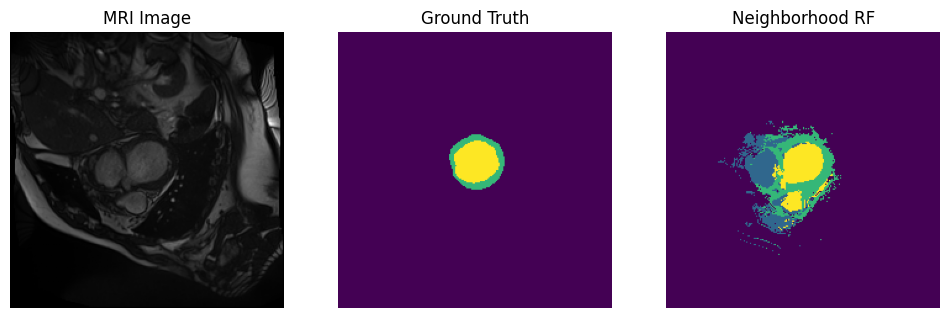

In [40]:
avg_3 = uniform_filter(val_image, size=3)
avg_7 = uniform_filter(val_image, size=7)

h, w = val_image.shape
yy, xx = np.indices(val_image.shape)

val_features_local = np.column_stack((
    val_image.ravel(),
    (xx / w).ravel(),
    (yy / h).ravel(),
    avg_3.ravel(),
    avg_7.ravel()
))

pred_mask_local = rf_seg_local.predict(val_features_local).reshape(val_image.shape)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(val_image.T, cmap="gray", origin="lower")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(val_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask_local.T, cmap="viridis", origin="lower", vmin=0, vmax=3)
plt.title("Neighborhood RF")
plt.axis("off")

plt.show()

### Extracting Features from Predicted Segmentations

We use the trained segmentation model to predict the ED and ES masks of each validation patient. From these masks, we calculate ventricular volumes, myocardium volume, and ejection fractions. These seven features will be passed to our existing Logistic Regression classifier to predict the cardiac condition.

In [41]:
predicted_features = []

for patient in sorted(val_patients):
    row = df[df["Patient"] == patient].iloc[0]
    patient_path = os.path.join(data_path, "training", patient)

    volumes = {}

    for phase in ["ED", "ES"]:
        frame = int(row[phase])
        image_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}.nii.gz")

        nii = nib.load(image_path)
        image = nii.get_fdata()
        voxel_volume = np.prod(nii.header.get_zooms()[:3]) / 1000

        predicted_volume = np.zeros(image.shape, dtype=np.uint8)

        for i in range(image.shape[2]):
            slice_image = image[:, :, i].astype(np.float32)
            slice_image = (slice_image - slice_image.mean()) / (slice_image.std() + 1e-8)

            h, w = slice_image.shape
            yy, xx = np.indices(slice_image.shape)

            avg_3 = uniform_filter(slice_image, size=3)
            avg_7 = uniform_filter(slice_image, size=7)

            pixel_features = np.column_stack((
                slice_image.ravel(),
                (xx / w).ravel(),
                (yy / h).ravel(),
                avg_3.ravel(),
                avg_7.ravel()
            ))

            predicted_volume[:, :, i] = rf_seg_local.predict(
                pixel_features
            ).reshape(slice_image.shape)

        volumes[phase] = {
            "LV": np.sum(predicted_volume == 3) * voxel_volume,
            "RV": np.sum(predicted_volume == 1) * voxel_volume,
            "MYO": np.sum(predicted_volume == 2) * voxel_volume
        }

    lv_ed = volumes["ED"]["LV"]
    lv_es = volumes["ES"]["LV"]
    rv_ed = volumes["ED"]["RV"]
    rv_es = volumes["ES"]["RV"]
    myo_ed = volumes["ED"]["MYO"]

    lv_ef = (lv_ed - lv_es) / lv_ed * 100 if lv_ed > 0 else 0
    rv_ef = (rv_ed - rv_es) / rv_ed * 100 if rv_ed > 0 else 0

    predicted_features.append({
        "Patient": patient,
        "Group": row["Group"],
        "LV_ED": lv_ed,
        "LV_ES": lv_es,
        "RV_ED": rv_ed,
        "RV_ES": rv_es,
        "MYO_ED": myo_ed,
        "LV_EF": lv_ef,
        "RV_EF": rv_ef
    })

predicted_features_df = pd.DataFrame(predicted_features)

print("Validation patients:", len(predicted_features_df))
print(predicted_features_df.head())

Validation patients: 20
      Patient Group       LV_ED       LV_ES       RV_ED       RV_ES  \
0  patient007   DCM  336.972656  324.773438  673.664062  672.996094   
1  patient008   DCM  213.159180  169.189453  357.763672  327.636719   
2  patient011   DCM  165.143634  153.267394  461.829295  461.146246   
3  patient015   DCM  183.967506  139.218653  364.495668  354.065484   
4  patient021   HCM  207.087097  137.399750  573.806183  560.827972   

       MYO_ED      LV_EF     RV_EF  
0  604.582031   3.620240  0.099155  
1  444.702148  20.627649  8.420909  
2  423.512447   7.191461  0.147901  
3  426.590776  24.324324  2.861538  
4  791.050140  33.651226  2.261776  


### Disease Classification Using Predicted Segmentations

We use the cardiac features extracted from the predicted segmentation masks as input to our previously trained Logistic Regression classifier. We evaluate classification accuracy and macro-F1 on the validation patients to measure the performance of the complete MRI-to-classification pipeline.

In [42]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

c_values = [0.01, 0.1, 1, 10, 100]
best_score = -1
best_c = None

for c in c_values:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=c, max_iter=1000, random_state=42)
    )

    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="f1_macro"
    )

    mean_score = scores.mean()
    print("C:", c, "Mean CV Macro-F1:", round(mean_score, 4))

    if mean_score > best_score:
        best_score = mean_score
        best_c = c

baseline_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=best_c, max_iter=1000, random_state=42)
)

baseline_classifier.fit(X_train, y_train)

X_predicted = predicted_features_df[feature_columns]
y_actual = predicted_features_df["Group"]

y_predicted = baseline_classifier.predict(X_predicted)

print()
print("Selected C:", best_c)
print("Validation Accuracy:", accuracy_score(y_actual, y_predicted))
print("Validation Macro-F1:", f1_score(y_actual, y_predicted, average="macro"))

print()
print(classification_report(y_actual, y_predicted, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_actual, y_predicted, labels=baseline_classifier.classes_))

C: 0.01 Mean CV Macro-F1: 0.8382
C: 0.1 Mean CV Macro-F1: 0.9045
C: 1 Mean CV Macro-F1: 0.9401
C: 10 Mean CV Macro-F1: 0.9401
C: 100 Mean CV Macro-F1: 0.9401

Selected C: 1
Validation Accuracy: 0.3
Validation Macro-F1: 0.16684491978609625

              precision    recall  f1-score   support

         DCM       0.31      1.00      0.47         4
         HCM       0.00      0.00      0.00         4
        MINF       0.00      0.00      0.00         4
         NOR       0.00      0.00      0.00         4
          RV       0.29      0.50      0.36         4

    accuracy                           0.30        20
   macro avg       0.12      0.30      0.17        20
weighted avg       0.12      0.30      0.17        20

Confusion Matrix:
[[4 0 0 0 0]
 [1 0 0 0 3]
 [3 0 0 0 1]
 [3 0 0 0 1]
 [2 0 0 0 2]]


### Classical Pipeline Results

The Random Forest segmentation model achieved a mean Dice score of 0.4046 on the 20 validation patients. The left ventricle had the highest Dice score (0.5589), followed by the myocardium (0.3378) and right ventricle (0.3169).

Using features extracted from these predicted masks, the Logistic Regression classifier achieved 30% accuracy and a macro-F1 of 0.1668. In comparison, cross-validation using features extracted from expert segmentation masks achieved a macro-F1 of 0.9401.

The results suggest that inaccurate segmentation significantly affects the cardiac measurements used for classification. Although the complete pipeline performs poorly, it provides a classical baseline for comparison with more advanced approaches, such as CNN-based segmentation.

### Final Segmentation Model

After selecting the segmentation approach using validation results, we retrain the Random Forest on all 100 training patients. We use the same five pixel features and hyperparameters before evaluating the complete pipeline on the 50 test patients.

In [43]:
X_seg_final = []
y_seg_final = []

rng = np.random.default_rng(42)

for image, mask in zip(seg_images, seg_masks):
    image = image.astype(np.float32)
    image = (image - image.mean()) / (image.std() + 1e-8)

    h, w = image.shape
    yy, xx = np.indices(image.shape)

    avg_3 = uniform_filter(image, size=3)
    avg_7 = uniform_filter(image, size=7)

    pixel_features = np.column_stack((
        image.ravel(),
        (xx / w).ravel(),
        (yy / h).ravel(),
        avg_3.ravel(),
        avg_7.ravel()
    ))

    labels = mask.ravel().astype(int)

    for label in range(4):
        indices = np.where(labels == label)[0]

        if len(indices) == 0:
            continue

        count = min(samples_per_class[label], len(indices))
        selected = rng.choice(indices, size=count, replace=False)

        X_seg_final.append(pixel_features[selected])
        y_seg_final.append(labels[selected])

X_seg_final = np.vstack(X_seg_final)
y_seg_final = np.concatenate(y_seg_final)

print("Training pixels:", X_seg_final.shape)
print("Class counts:", np.unique(y_seg_final, return_counts=True))

Training pixels: (1930313, 5)
Class counts: (array([0, 1, 2, 3]), array([951000, 285354, 360595, 333364]))


### Training the Final Segmentation Model

We train the final Random Forest segmentation model using all 100 training patients. We keep the same hyperparameters selected during development and will evaluate the model on the 50 official testing patients.

In [44]:
rf_seg_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_seg_final.fit(X_seg_final, y_seg_final)

print("Final Random Forest training completed")
print("Training pixels:", len(X_seg_final))
print("Number of features:", X_seg_final.shape[1])

Final Random Forest training completed
Training pixels: 1930313
Number of features: 5


### Final Segmentation Evaluation

We evaluate the final Random Forest segmentation model on the 50 official test patients. We calculate Dice scores for the right ventricle, myocardium, and left ventricle by comparing the predicted masks with the expert segmentation masks. The test patients were not used during training or model selection.

In [45]:
test_dice_results = []

for _, row in df[df["Split"] == "testing"].iterrows():
    patient = row["Patient"]
    patient_path = os.path.join(data_path, "testing", patient)

    intersections = np.zeros(3)
    predicted_counts = np.zeros(3)
    actual_counts = np.zeros(3)

    for phase in ["ED", "ES"]:
        frame = int(row[phase])

        image_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}.nii.gz")
        mask_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}_gt.nii.gz")

        image = nib.load(image_path).get_fdata()
        mask = nib.load(mask_path).get_fdata()

        for i in range(image.shape[2]):
            slice_image = image[:, :, i].astype(np.float32)
            slice_image = (slice_image - slice_image.mean()) / (slice_image.std() + 1e-8)

            h, w = slice_image.shape
            yy, xx = np.indices(slice_image.shape)

            avg_3 = uniform_filter(slice_image, size=3)
            avg_7 = uniform_filter(slice_image, size=7)

            pixel_features = np.column_stack((
                slice_image.ravel(),
                (xx / w).ravel(),
                (yy / h).ravel(),
                avg_3.ravel(),
                avg_7.ravel()
            ))

            prediction = rf_seg_final.predict(pixel_features).reshape(slice_image.shape)
            actual_slice = mask[:, :, i]

            for label in range(1, 4):
                predicted = prediction == label
                actual = actual_slice == label

                intersections[label - 1] += np.sum(predicted & actual)
                predicted_counts[label - 1] += np.sum(predicted)
                actual_counts[label - 1] += np.sum(actual)

    scores = []

    for i in range(3):
        total = predicted_counts[i] + actual_counts[i]
        dice = 2 * intersections[i] / total if total > 0 else 1.0
        scores.append(dice)

    test_dice_results.append({
        "Patient": patient,
        "RV": scores[0],
        "Myocardium": scores[1],
        "LV": scores[2]
    })

test_dice_df = pd.DataFrame(test_dice_results)

print("Mean Dice on Test Patients:")
print(test_dice_df[["RV", "Myocardium", "LV"]].mean().round(4))

print("Overall Mean Dice:", round(
    test_dice_df[["RV", "Myocardium", "LV"]].mean().mean(), 4
))

Mean Dice on Test Patients:
RV            0.3400
Myocardium    0.3428
LV            0.5379
dtype: float64
Overall Mean Dice: 0.4069


### Extracting Cardiac Features from Test Predictions

We use the final Random Forest segmentation model to predict ED and ES masks for the 50 test patients. From these predicted masks, we calculate the same seven cardiac measurements used by our Logistic Regression classifier. This allows us to evaluate disease classification using only the MRI images and the ED/ES frame information.

In [46]:
test_predicted_features = []

for _, row in df[df["Split"] == "testing"].iterrows():
    patient = row["Patient"]
    patient_path = os.path.join(data_path, "testing", patient)

    volumes = {}

    for phase in ["ED", "ES"]:
        frame = int(row[phase])
        image_path = os.path.join(patient_path, f"{patient}_frame{frame:02d}.nii.gz")

        nii = nib.load(image_path)
        image = nii.get_fdata()
        voxel_volume = np.prod(nii.header.get_zooms()[:3]) / 1000

        predicted_volume = np.zeros(image.shape, dtype=np.uint8)

        for i in range(image.shape[2]):
            slice_image = image[:, :, i].astype(np.float32)
            slice_image = (slice_image - slice_image.mean()) / (slice_image.std() + 1e-8)

            h, w = slice_image.shape
            yy, xx = np.indices(slice_image.shape)

            avg_3 = uniform_filter(slice_image, size=3)
            avg_7 = uniform_filter(slice_image, size=7)

            pixel_features = np.column_stack((
                slice_image.ravel(),
                (xx / w).ravel(),
                (yy / h).ravel(),
                avg_3.ravel(),
                avg_7.ravel()
            ))

            predicted_volume[:, :, i] = rf_seg_final.predict(
                pixel_features
            ).reshape(slice_image.shape)

        volumes[phase] = {
            "LV": np.sum(predicted_volume == 3) * voxel_volume,
            "RV": np.sum(predicted_volume == 1) * voxel_volume,
            "MYO": np.sum(predicted_volume == 2) * voxel_volume
        }

    lv_ed = volumes["ED"]["LV"]
    lv_es = volumes["ES"]["LV"]
    rv_ed = volumes["ED"]["RV"]
    rv_es = volumes["ES"]["RV"]
    myo_ed = volumes["ED"]["MYO"]

    lv_ef = (lv_ed - lv_es) / lv_ed * 100 if lv_ed > 0 else 0
    rv_ef = (rv_ed - rv_es) / rv_ed * 100 if rv_ed > 0 else 0

    test_predicted_features.append({
        "Patient": patient,
        "Group": row["Group"],
        "LV_ED": lv_ed,
        "LV_ES": lv_es,
        "RV_ED": rv_ed,
        "RV_ES": rv_es,
        "MYO_ED": myo_ed,
        "LV_EF": lv_ef,
        "RV_EF": rv_ef
    })

test_predicted_features_df = pd.DataFrame(test_predicted_features)

print("Test patients:", len(test_predicted_features_df))
print(test_predicted_features_df.head())

Test patients: 50
      Patient Group       LV_ED       LV_ES       RV_ED       RV_ES  \
0  patient101   DCM  285.636200  240.551331  526.995021  521.234924   
1  patient102   NOR  170.776367  125.585938  581.884766  583.032227   
2  patient103  MINF  157.788086  130.590820  278.125000  255.444336   
3  patient104   HCM  137.218600   67.235432  352.514041  329.092858   
4  patient105   HCM  140.818274   94.392972  444.907306  426.839557   

       MYO_ED      LV_EF     RV_EF  
0  556.091584  15.784018  1.093008  
1  328.540039  26.461758 -0.197197  
2  414.282227  17.236577  8.154846  
3  379.673641  51.001226  6.644043  
4  468.946226  32.968237  4.061014  


### Final Classification Evaluation

We use the cardiac measurements extracted from the Random Forest's predicted segmentation masks to classify the 50 test patients. The Logistic Regression classifier was trained on all 100 training patients using features extracted from expert masks. We evaluate the complete pipeline using accuracy, macro-F1, a classification report, and a confusion matrix.

In [47]:
X_test_rf = test_predicted_features_df[feature_columns]
y_test_rf = test_predicted_features_df["Group"]

y_pred_rf = final_model.predict(X_test_rf)

print("Model 2 Test Accuracy:", accuracy_score(y_test_rf, y_pred_rf))
print("Model 2 Test Macro-F1:", f1_score(y_test_rf, y_pred_rf, average="macro"))

print()
print(classification_report(y_test_rf, y_pred_rf, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test_rf, y_pred_rf, labels=final_model.classes_))

Model 2 Test Accuracy: 0.28
Model 2 Test Macro-F1: 0.1627586206896552

              precision    recall  f1-score   support

         DCM       0.27      0.80      0.40        10
         HCM       0.00      0.00      0.00        10
        MINF       0.00      0.00      0.00        10
         NOR       0.00      0.00      0.00        10
          RV       0.32      0.60      0.41        10

    accuracy                           0.28        50
   macro avg       0.12      0.28      0.16        50
weighted avg       0.12      0.28      0.16        50

Confusion Matrix:
[[8 0 0 0 2]
 [6 0 0 0 4]
 [9 0 0 0 1]
 [3 0 1 0 6]
 [4 0 0 0 6]]


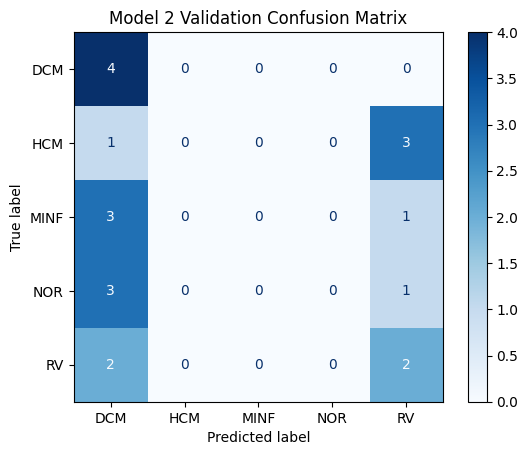

In [48]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

classes = ["DCM", "HCM", "MINF", "NOR", "RV"]

cm = np.array([
    [4, 0, 0, 0, 0],
    [1, 0, 0, 0, 3],
    [3, 0, 0, 0, 1],
    [3, 0, 0, 0, 1],
    [2, 0, 0, 0, 2]
])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(cmap="Blues")

plt.title("Model 2 Validation Confusion Matrix")
plt.show()

### Final Classical Model Results

Both classical approaches were evaluated on the same 50 official test patients.

Model 1, which uses cardiac measurements extracted from expert segmentation masks, achieved 90% classification accuracy and a macro-F1 of 0.8999.

Model 2 uses a Random Forest to automatically segment the MRI images before extracting the same cardiac measurements. Its segmentation model achieved a mean Dice score of 0.4069, while the complete classification pipeline achieved 28% accuracy and a macro-F1 of 0.1628.

The large difference between the two models suggests that segmentation quality is important for accurate disease classification. The Random Forest produces inaccurate cardiac measurements, particularly for the right ventricle and myocardium, which affects the classifier's predictions. Additionally, the classifier was trained using expert-mask measurements rather than predicted-mask measurements, creating a mismatch between training and testing inputs.

Although Model 2 performs poorly, it provides a classical automatic-segmentation baseline for comparison with the CNN-based approach.

## Part 3: Level 2 - Deep-Learning Segmentation (2D U-Net) Followed by Classification

Parts 1 and 2 gave us two classical references:

* **Model 1** - expert masks -> 7 cardiac measurements -> Logistic Regression (upper bound, needs expert masks).
* **Model 2** - Random Forest pixel classifier -> predicted masks -> same 7 measurements -> same Logistic Regression (Dice about 0.40, accuracy about 0.3).

Here we investigate the Level 2 method: a **2D U-Net** that replaces the Random Forest segmenter. **Only the segmentation stage changes**: the predicted ED/ES masks go through the *same* feature extraction and the *same* Logistic Regression (`final_model`, trained on expert-mask features), so any difference in classification accuracy is attributable to the segmentation model.

We also check whether a more complex *classifier* (Random Forest, Gradient Boosting, small neural network) helps once the measurements are given.

**Protocol (to avoid test leakage):** every design decision here (epochs, post-processing) is made on the 80/20 train/validation patient split from Part 1 (`train_patients`, `val_patients`). The 50 test patients are touched only once, in the last section.

### Setup and Configuration

Configuration lives in one place. Set `QUICK_RUN = True` for a 2-epoch smoke test (to check that everything runs end-to-end before launching a full training). A GPU is strongly recommended for the full run (e.g. a free Colab T4); on CPU each epoch can take minutes.

In [49]:
import time, math, gc
import joblib, warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
from scipy import ndimage
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# ---------------- Configuration ----------------
SEED       = 42
CROP       = 160     # slices are centre-cropped / zero-padded to CROP x CROP (must be divisible by 16)
BASE       = 16      # number of filters in the first U-Net level
EPOCHS     = 40
BATCH      = 16
LR         = 1e-3
QUICK_RUN  = False   # True -> 2 epochs, just to test that the pipeline runs
if QUICK_RUN:
    EPOCHS = 2
assert CROP % 16 == 0

# Free the large arrays created by the Random Forest experiments (Part 2); Part 3 loads its own data
for _name in ["seg_images", "seg_masks", "X_seg_train", "y_seg_train", "X_seg_balanced", "y_seg_balanced",
              "X_seg_improved", "y_seg_improved", "X_seg_local", "y_seg_local", "X_seg_final", "y_seg_final"]:
    globals().pop(_name, None)
gc.collect()
print("Config:", dict(CROP=CROP, BASE=BASE, EPOCHS=EPOCHS, BATCH=BATCH, LR=LR))

Config: {'CROP': 160, 'BASE': 16, 'EPOCHS': 40, 'BATCH': 16, 'LR': 0.001}


In [50]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.10.0+cu130 | device: cuda


### U-Net Data Preparation

For every patient we load the ED and ES volumes and their expert masks (same frames as before, taken from `Info.cfg`). Differences from the Random Forest pipeline, and why:

* **Intensity normalization per 3D volume** (clip at the 1st/99th percentile, then z-score) instead of per slice, so that neighbouring slices share the same intensity scale.
* **Fixed input size**: ACDC images have different in-plane sizes, so each slice is centre-cropped (or zero-padded) to `CROP x CROP`. The cropped region contains the heart for almost all patients; we *measure* how much expert-mask foreground the crop loses instead of assuming it.
* Ground-truth voxel counts are always taken from the **full-size** expert masks, so Dice and volumes are comparable with the Random Forest results (no advantage from cropping).

In [51]:
def normalize_volume(v):
    # Clip extreme intensities, then z-score the whole 3D volume.
    v = v.astype(np.float32)
    lo, hi = np.percentile(v, [1, 99])
    v = np.clip(v, lo, hi)
    return (v - v.mean()) / (v.std() + 1e-8)


def center_crop_pad(a, size, value=0):
    # Centre-crop (if larger) or zero-pad (if smaller) the first two axes to size x size.
    h, w = a.shape[:2]
    out = np.full((size, size) + a.shape[2:], value, dtype=a.dtype)
    sy, sx = max((h - size) // 2, 0), max((w - size) // 2, 0)
    dy, dx = max((size - h) // 2, 0), max((size - w) // 2, 0)
    ch, cw = min(h, size), min(w, size)
    out[dy:dy + ch, dx:dx + cw] = a[sy:sy + ch, sx:sx + cw]
    return out


def build_slices(patient_rows):
    # Returns cropped slices X (N,1,CROP,CROP), cropped masks Y (N,CROP,CROP) and a metadata table.
    # Metadata keeps the voxel volume and the FULL-SIZE expert voxel counts (G1=RV, G2=MYO, G3=LV).
    Xs, Ys, meta = [], [], []
    for _, row in patient_rows.iterrows():
        patient, split = row["Patient"], row["Split"]
        folder = os.path.join(data_path, split, patient)
        for phase in ["ED", "ES"]:
            frame = int(row[phase])
            img_nii = nib.load(os.path.join(folder, f"{patient}_frame{frame:02d}.nii.gz"))
            msk_nii = nib.load(os.path.join(folder, f"{patient}_frame{frame:02d}_gt.nii.gz"))
            img = normalize_volume(img_nii.get_fdata())
            msk = np.rint(msk_nii.get_fdata()).astype(np.uint8)
            voxel = float(np.prod(img_nii.header.get_zooms()[:3])) / 1000   # mL per voxel (same as Part 1)
            for i in range(img.shape[2]):
                Xs.append(center_crop_pad(img[:, :, i], CROP))
                Ys.append(center_crop_pad(msk[:, :, i], CROP))
                meta.append({"Patient": patient, "Phase": phase, "Slice": i, "Voxel": voxel,
                             "G1": int((msk[:, :, i] == 1).sum()),
                             "G2": int((msk[:, :, i] == 2).sum()),
                             "G3": int((msk[:, :, i] == 3).sum())})
    X = np.stack(Xs)[:, None].astype(np.float32)
    Y = np.stack(Ys).astype(np.uint8)
    return X, Y, pd.DataFrame(meta)

In [52]:
rows_dev_train = df[df["Patient"].isin(train_patients)]    # same 80 patients as Part 1 / Part 2
rows_dev_val   = df[df["Patient"].isin(val_patients)]      # same 20 patients as Part 1 / Part 2
rows_test      = df[df["Split"] == "testing"]              # 50 official test patients (used only at the very end)

t0 = time.time()
X_tr, Y_tr, meta_tr = build_slices(rows_dev_train)
X_va, Y_va, meta_va = build_slices(rows_dev_val)
print(f"Loaded in {time.time() - t0:.0f}s")
print("Train slices:", X_tr.shape, "| Val slices:", X_va.shape)
print("Train patients:", meta_tr['Patient'].nunique(), "| Val patients:", meta_va['Patient'].nunique())

# Sanity check: how much expert-mask foreground does the centre crop keep?
for name, Y, meta in [("train", Y_tr, meta_tr), ("val", Y_va, meta_va)]:
    kept = [(Y == l).sum() / meta[f"G{l}"].sum() for l in (1, 2, 3)]
    print(f"{name}: fraction of expert RV / MYO / LV voxels inside the crop:", np.round(kept, 4))

Loaded in 4s
Train slices: (1504, 1, 160, 160) | Val slices: (398, 1, 160, 160)
Train patients: 80 | Val patients: 20
train: fraction of expert RV / MYO / LV voxels inside the crop: [0.9886 1.     1.    ]
val: fraction of expert RV / MYO / LV voxels inside the crop: [0.9966 0.997  1.    ]


### U-Net Model

A standard 2D U-Net (Ronneberger et al., 2015): four down-sampling levels (conv-BN-ReLU blocks + max-pooling), a bottleneck, and four up-sampling levels with skip connections. The input is one MRI slice and the output is a 4-class label map (background, RV, myocardium, LV). It is trained slice by slice with a combined **cross-entropy + soft-Dice loss**: cross-entropy gives stable pixel-wise gradients, while the Dice term directly optimizes the overlap metric and handles the extreme background/foreground imbalance without the resampling hack that distorted the Random Forest's class priors.

Training uses random rotation (+-15 deg), scaling (+-10%), translation and intensity jitter. We deliberately do **not** flip images, because left/right flipping would swap the anatomical position of the RV and LV.

In [53]:
class DoubleConv(nn.Module):
    def __init__(self, c_in, c_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=4, base=16):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc1, self.enc2 = DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1])
        self.enc3, self.enc4 = DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])
        self.bottleneck = DoubleConv(c[3], c[4])
        self.pool = nn.MaxPool2d(2)
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, stride=2), DoubleConv(c[3] * 2, c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, stride=2), DoubleConv(c[2] * 2, c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, stride=2), DoubleConv(c[1] * 2, c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, stride=2), DoubleConv(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], n_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)


def soft_dice_loss(logits, target, n_classes=4, eps=1e-6):
    # 1 - mean soft Dice over the 3 foreground classes (background is excluded from the average)
    probs = F.softmax(logits, dim=1)
    onehot = F.one_hot(target, n_classes).permute(0, 3, 1, 2).float()
    inter = (probs * onehot).sum(dim=(0, 2, 3))
    denom = probs.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))
    dice = (2 * inter + eps) / (denom + eps)
    return 1 - dice[1:].mean()


def augment(x, y):
    # Random affine (rotation, scale, shift) applied identically to image and mask + intensity jitter.
    B = x.size(0)
    dev = x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(15)
    scale = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.10
    tx = (torch.rand(B, device=dev) * 2 - 1) * 0.10
    ty = (torch.rand(B, device=dev) * 2 - 1) * 0.10
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], dim=1),
                         torch.stack([sin, cos, ty], dim=1)], dim=1)          # (B, 2, 3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    y = F.grid_sample(y.unsqueeze(1).float(), grid, mode="nearest", padding_mode="zeros",
                      align_corners=False).squeeze(1).long()
    x = x * (1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.2) + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.2
    return x, y


@torch.no_grad()
def predict_slices(model, X, batch_size=64):
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        xb = torch.from_numpy(X[i:i + batch_size]).to(device)
        out.append(model(xb).argmax(dim=1).cpu().numpy().astype(np.uint8))
    return np.concatenate(out)


def quick_val_dice(model, X, Y):
    # Mean Dice over RV/MYO/LV pooled over all slices (cropped region) - only used to monitor training.
    pred = predict_slices(model, X)
    ds = []
    for l in (1, 2, 3):
        p, g = pred == l, Y == l
        ds.append(2 * (p & g).sum() / max(p.sum() + g.sum(), 1))
    return float(np.mean(ds))


def train_unet(X, Y, epochs, X_val=None, Y_val=None, base=BASE, lr=LR, batch_size=BATCH, seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = UNet(base=base).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    Xt, Yt = torch.from_numpy(X), torch.from_numpy(Y)
    history, t0 = [], time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        total = 0.0
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:          # BatchNorm needs more than one sample
                continue
            xb, yb = Xt[idx].to(device), Yt[idx].long().to(device)
            xb, yb = augment(xb, yb)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb) + soft_dice_loss(logits, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        sched.step()
        rec = {"epoch": ep + 1, "train_loss": total / len(Xt)}
        if X_val is not None:
            rec["val_dice"] = quick_val_dice(model, X_val, Y_val)
        history.append(rec)
        print(" | ".join(f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}" for k, v in rec.items())
              + f" | {time.time() - t0:.0f}s")
    return model, pd.DataFrame(history), time.time() - t0

In [54]:
# Smoke test: check shapes, parameter count and that one optimisation step runs, BEFORE the long training.
_m = UNet(base=BASE).to(device)
n_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
_xb = torch.from_numpy(X_tr[:4]).to(device)
_yb = torch.from_numpy(Y_tr[:4]).long().to(device)
_xa, _ya = augment(_xb, _yb)
_out = _m(_xa)
assert _out.shape == (4, 4, CROP, CROP), _out.shape
_loss = F.cross_entropy(_out, _ya) + soft_dice_loss(_out, _ya)
_loss.backward()
print(f"U-Net parameters: {n_params:,} | output shape: {tuple(_out.shape)} | initial loss: {_loss.item():.3f}")
print("Labels after augmentation:", torch.unique(_ya).tolist())
del _m, _xb, _yb, _xa, _ya, _out, _loss

U-Net parameters: 1,942,340 | output shape: (4, 4, 160, 160) | initial loss: 2.524
Labels after augmentation: [0, 1, 2, 3]


### Training the U-Net (development split)

We train on the 80 development-training patients and monitor Dice on the 20 validation patients after each epoch. This is the same split used for the Random Forest, so the comparison is like-for-like.

In [55]:
unet_dev, hist_dev, train_time_dev = train_unet(X_tr, Y_tr, EPOCHS, X_va, Y_va)
print(f"\nTraining time (80 patients, {EPOCHS} epochs): {train_time_dev / 60:.1f} min on {device}")

epoch: 1 | train_loss: 1.7886 | val_dice: 0.6598 | 6s
epoch: 2 | train_loss: 1.0004 | val_dice: 0.7185 | 11s
epoch: 3 | train_loss: 0.5039 | val_dice: 0.8373 | 16s
epoch: 4 | train_loss: 0.2991 | val_dice: 0.8453 | 21s
epoch: 5 | train_loss: 0.2308 | val_dice: 0.8702 | 26s
epoch: 6 | train_loss: 0.2035 | val_dice: 0.7970 | 31s
epoch: 7 | train_loss: 0.1827 | val_dice: 0.8619 | 36s
epoch: 8 | train_loss: 0.1637 | val_dice: 0.8906 | 41s
epoch: 9 | train_loss: 0.1508 | val_dice: 0.8910 | 46s
epoch: 10 | train_loss: 0.1492 | val_dice: 0.8857 | 51s
epoch: 11 | train_loss: 0.1407 | val_dice: 0.8817 | 56s
epoch: 12 | train_loss: 0.1360 | val_dice: 0.8909 | 61s
epoch: 13 | train_loss: 0.1390 | val_dice: 0.8599 | 66s
epoch: 14 | train_loss: 0.1231 | val_dice: 0.8965 | 71s
epoch: 15 | train_loss: 0.1204 | val_dice: 0.8925 | 76s
epoch: 16 | train_loss: 0.1266 | val_dice: 0.8892 | 81s
epoch: 17 | train_loss: 0.1177 | val_dice: 0.8892 | 86s
epoch: 18 | train_loss: 0.1126 | val_dice: 0.8934 | 91s
ep

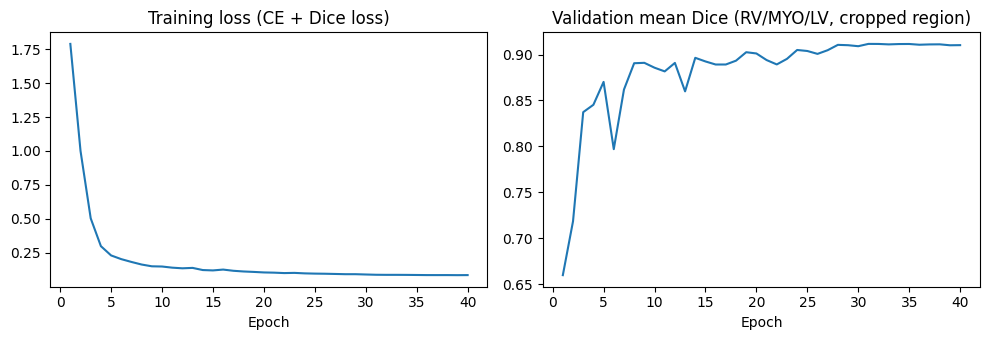

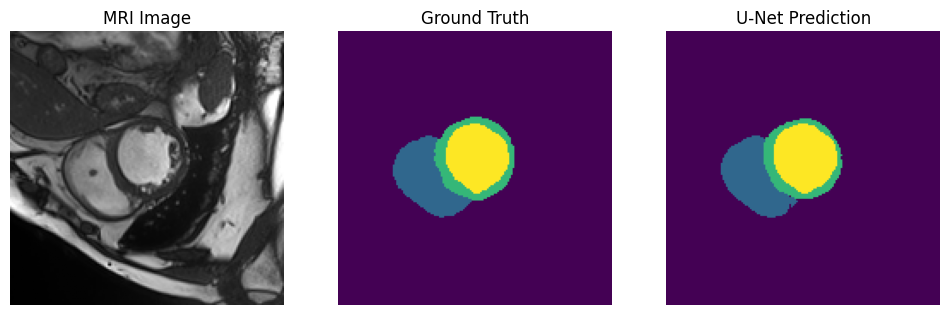

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist_dev["epoch"], hist_dev["train_loss"]); ax[0].set_title("Training loss (CE + Dice loss)"); ax[0].set_xlabel("Epoch")
ax[1].plot(hist_dev["epoch"], hist_dev["val_dice"]); ax[1].set_title("Validation mean Dice (RV/MYO/LV, cropped region)"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

# Qualitative example: same validation patient as Part 2, ED phase, slice with the largest expert LV area
vp = sorted(val_patients)[0]
cand = meta_va[(meta_va["Patient"] == vp) & (meta_va["Phase"] == "ED")]
k = cand["G3"].idxmax()
pred_k = predict_slices(unet_dev, X_va[k:k + 1])[0]

plt.figure(figsize=(12, 4))
for j, (img, title, kw) in enumerate([(X_va[k, 0], "MRI Image", dict(cmap="gray")),
                                      (Y_va[k], "Ground Truth", dict(cmap="viridis", vmin=0, vmax=3)),
                                      (pred_k, "U-Net Prediction", dict(cmap="viridis", vmin=0, vmax=3))]):
    plt.subplot(1, 3, j + 1)
    plt.imshow(img.T, origin="lower", **kw)
    plt.title(title); plt.axis("off")
plt.show()

### Evaluation Helpers

These functions turn per-slice predictions into (a) per-patient Dice scores, computed exactly as in Part 2 (ED and ES slices pooled per patient, against the **full-size** expert masks), (b) the same seven cardiac measurements as Part 1, and (c) an optional 3D post-processing step that keeps only the largest connected component of each structure (a standard clean-up that removes isolated false-positive blobs).

In [57]:
STRUCTS = [(1, "RV"), (2, "Myocardium"), (3, "LV")]
group_of = df.set_index("Patient")["Group"]


def eval_predictions(meta, pred, Y):
    # Adds predicted voxel counts (P1..P3) and intersections with the expert mask (I1..I3) to the metadata table.
    m = meta.copy()
    for l, _ in STRUCTS:
        p, g = (pred == l), (Y == l)
        m[f"P{l}"] = p.reshape(len(p), -1).sum(axis=1)
        m[f"I{l}"] = (p & g).reshape(len(p), -1).sum(axis=1)
    return m


def patient_dice(m):
    # Per-patient Dice per structure (ED + ES pooled), denominators use FULL-SIZE expert voxel counts.
    cols = [f"{a}{l}" for a in "PGI" for l, _ in STRUCTS]
    g = m.groupby("Patient")[cols].sum()
    out = pd.DataFrame(index=g.index)
    for l, name in STRUCTS:
        tot = g[f"P{l}"] + g[f"G{l}"]
        out[name] = np.where(tot > 0, 2 * g[f"I{l}"] / tot.replace(0, 1), 1.0)
    return out.reset_index()


def features_from_predictions(m):
    # Same seven measurements as Part 1 (volumes in mL, ejection fractions in %), computed from predicted masks.
    rows = []
    for patient, g in m.groupby("Patient", sort=True):
        vol = {}
        for phase in ["ED", "ES"]:
            gp = g[g["Phase"] == phase]
            v = gp["Voxel"].iloc[0]
            vol[phase] = {"RV": gp["P1"].sum() * v, "MYO": gp["P2"].sum() * v, "LV": gp["P3"].sum() * v}
        lv_ed, lv_es = vol["ED"]["LV"], vol["ES"]["LV"]
        rv_ed, rv_es = vol["ED"]["RV"], vol["ES"]["RV"]
        rows.append({"Patient": patient, "Group": group_of[patient],
                     "LV_ED": lv_ed, "LV_ES": lv_es, "RV_ED": rv_ed, "RV_ES": rv_es,
                     "MYO_ED": vol["ED"]["MYO"],
                     "LV_EF": (lv_ed - lv_es) / lv_ed * 100 if lv_ed > 0 else 0,
                     "RV_EF": (rv_ed - rv_es) / rv_ed * 100 if rv_ed > 0 else 0})
    return pd.DataFrame(rows)


def postprocess_3d(pred, meta):
    # For each (patient, phase) volume keep only the largest 3D connected component of RV, MYO and LV.
    out = pred.copy()
    for _, idx in meta.groupby(["Patient", "Phase"]).indices.items():
        vol = out[idx]
        for l, _ in STRUCTS:
            mask = vol == l
            lab, n = ndimage.label(mask)
            if n > 1:
                sizes = np.bincount(lab.ravel())[1:]
                vol[mask & (lab != 1 + int(np.argmax(sizes)))] = 0
        out[idx] = vol
    return out


def feature_error_table(pred_feat_df, reference_df=None):
    # Mean absolute error and correlation between predicted-mask features and expert-mask features.
    ref = features_df.set_index("Patient").loc[pred_feat_df["Patient"], feature_columns]
    prd = pred_feat_df.set_index("Patient")[feature_columns]
    return pd.DataFrame({"MAE": (prd - ref).abs().mean(),
                         "Pearson r": [np.corrcoef(prd[c], ref[c])[0, 1] for c in feature_columns]})

### Validation Results: Segmentation and Classification

We compare, on the same 20 validation patients: (1) per-structure Dice of the Random Forest (Part 2) vs. the U-Net, (2) whether the 3D largest-component post-processing helps (decided on validation Dice only), and (3) the classification obtained by feeding each model's predicted-mask features to the Logistic Regression trained on expert-mask features of the 80 development-training patients.

In [58]:
# ---- (1) segmentation quality on validation patients ----
pred_va_raw = predict_slices(unet_dev, X_va)
m_va_raw = eval_predictions(meta_va, pred_va_raw, Y_va)
dice_va_raw = patient_dice(m_va_raw)

# ---- (2) is 3D largest-component post-processing useful? (decided on validation data only) ----
pred_va_pp = postprocess_3d(pred_va_raw, meta_va)
m_va_pp = eval_predictions(meta_va, pred_va_pp, Y_va)
dice_va_pp = patient_dice(m_va_pp)

cols = [n for _, n in STRUCTS]
seg_table = pd.DataFrame({
    "Random Forest (Part 2)": dice_local_df[cols].mean(),
    "U-Net": dice_va_raw[cols].mean(),
    "U-Net + largest-component": dice_va_pp[cols].mean()})
seg_table.loc["Mean"] = seg_table.mean()
print("Validation Dice (20 patients):")
print(seg_table.round(4))

USE_POSTPROC = bool(dice_va_pp[cols].mean().mean() > dice_va_raw[cols].mean().mean())
print("\nUse post-processing:", USE_POSTPROC)
m_va = m_va_pp if USE_POSTPROC else m_va_raw
dice_va = dice_va_pp if USE_POSTPROC else dice_va_raw

# ---- (3) classification from predicted-mask features ----
unet_val_features = features_from_predictions(m_va)

# Development classifier: Logistic Regression (C=1.0, selected by CV in Part 1) trained on EXPERT-mask features of the 80 dev-training patients
clf_dev = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, random_state=42))
clf_dev.fit(X_train, y_train)

def clf_report(name, feat_df):
    pred = clf_dev.predict(feat_df[feature_columns])
    return {"Pipeline": name,
            "Accuracy": accuracy_score(feat_df["Group"], pred),
            "Macro-F1": f1_score(feat_df["Group"], pred, average="macro"), "pred": pred}

val_expert = features_df[features_df["Patient"].isin(val_patients)].sort_values("Patient").reset_index(drop=True)
res = [clf_report("Expert masks -> LR (upper bound)", val_expert),
       clf_report("Random Forest masks -> LR", predicted_features_df.sort_values("Patient").reset_index(drop=True)),
       clf_report("U-Net masks -> LR", unet_val_features)]
print("\nValidation classification (20 patients):")
print(pd.DataFrame(res)[["Pipeline", "Accuracy", "Macro-F1"]].round(4).to_string(index=False))

print("\nU-Net pipeline confusion matrix (rows = actual, columns = predicted):", list(clf_dev.classes_))
print(confusion_matrix(unet_val_features["Group"], res[2]["pred"], labels=clf_dev.classes_))
print(classification_report(unet_val_features["Group"], res[2]["pred"], zero_division=0))

# ---- how segmentation errors propagate into the measurements ----
print("Error of the 7 measurements w.r.t. expert masks (validation):")
print(pd.concat({"Random Forest": feature_error_table(predicted_features_df),
                 "U-Net": feature_error_table(unet_val_features)}, axis=1).round(3))

Validation Dice (20 patients):
            Random Forest (Part 2)   U-Net  U-Net + largest-component
RV                          0.3169  0.8860                     0.8872
Myocardium                  0.3378  0.8811                     0.8814
LV                          0.5589  0.9536                     0.9538
Mean                        0.4046  0.9069                     0.9075

Use post-processing: True

Validation classification (20 patients):
                        Pipeline  Accuracy  Macro-F1
Expert masks -> LR (upper bound)      0.85    0.8521
       Random Forest masks -> LR      0.30    0.1668
               U-Net masks -> LR      0.70    0.6931

U-Net pipeline confusion matrix (rows = actual, columns = predicted): ['DCM', 'HCM', 'MINF', 'NOR', 'RV']
[[3 0 1 0 0]
 [0 2 0 1 1]
 [1 0 3 0 0]
 [0 0 0 4 0]
 [0 0 0 2 2]]
              precision    recall  f1-score   support

         DCM       0.75      0.75      0.75         4
         HCM       1.00      0.50      0.67         4
  

### Does a More Complex Classifier Help? (expert-mask features)

Independently of segmentation, we check whether the seven measurements are better exploited by a more flexible classifier than Logistic Regression. We use repeated stratified 5-fold cross-validation (3 repeats) on the 100 training patients. This is a Level 2 comparison for the *classification* stage: Random Forest, Gradient Boosting and a small neural network (MLP) against the tuned Logistic Regression. Note that the MLP/RF/GB settings are not heavily tuned; a few reasonable settings are tried for the MLP.

In [59]:
X_gt, y_gt = train_df[feature_columns], train_df["Group"]
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

candidates = {
    "Logistic Regression (C=1)": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
    "Random Forest (300 trees)": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient Boosting":         GradientBoostingClassifier(random_state=SEED),
    "MLP (16), alpha=1e-2":      make_pipeline(StandardScaler(), MLPClassifier((16,), alpha=1e-2, max_iter=3000, random_state=SEED)),
    "MLP (32,16), alpha=1e-2":   make_pipeline(StandardScaler(), MLPClassifier((32, 16), alpha=1e-2, max_iter=3000, random_state=SEED)),
    "MLP (32,16), alpha=1e-1":   make_pipeline(StandardScaler(), MLPClassifier((32, 16), alpha=1e-1, max_iter=3000, random_state=SEED)),
}

rows = []
for name, model in candidates.items():
    cvres = cross_validate(model, X_gt, y_gt, cv=rcv, scoring="f1_macro")
    rows.append({"Classifier": name,
                 "CV Macro-F1": cvres["test_score"].mean(),
                 "Std": cvres["test_score"].std(),
                 "Fit time / fold (s)": cvres["fit_time"].mean()})
clf_compare_df = pd.DataFrame(rows)
print(clf_compare_df.round(4).to_string(index=False))

               Classifier  CV Macro-F1    Std  Fit time / fold (s)
Logistic Regression (C=1)       0.9258 0.0604               0.0043
Random Forest (300 trees)       0.8608 0.0745               0.2483
        Gradient Boosting       0.7937 0.0848               0.1852
     MLP (16), alpha=1e-2       0.9385 0.0433               0.1303
  MLP (32,16), alpha=1e-2       0.9217 0.0530               0.1171
  MLP (32,16), alpha=1e-1       0.9220 0.0558               0.1109


### Final U-Net and Held-Out Test Evaluation

Having chosen the configuration (architecture, number of epochs and post-processing) on the validation split, we retrain the U-Net on all 100 official training patients with the *same* settings (mirroring what was done for the Random Forest), save the weights for the GitHub repository, and evaluate **once** on the 50 test patients. The classifier is the Logistic Regression `final_model` from Part 1 (trained on expert-mask features of the 100 training patients).

In [60]:
X_all = np.concatenate([X_tr, X_va])
Y_all = np.concatenate([Y_tr, Y_va])

unet_final, hist_final, train_time_final = train_unet(X_all, Y_all, EPOCHS)
print(f"\nFinal training time (100 patients, {EPOCHS} epochs): {train_time_final / 60:.1f} min on {device}")

os.makedirs("models", exist_ok=True)
torch.save(unet_final.state_dict(), "models/unet_final.pt")
joblib.dump(final_model, "models/logreg_final.joblib")
print("Saved: models/unet_final.pt, models/logreg_final.joblib")

epoch: 1 | train_loss: 1.6881 | 6s
epoch: 2 | train_loss: 0.7869 | 12s
epoch: 3 | train_loss: 0.3474 | 17s
epoch: 4 | train_loss: 0.2305 | 23s
epoch: 5 | train_loss: 0.2019 | 29s
epoch: 6 | train_loss: 0.1720 | 34s
epoch: 7 | train_loss: 0.1761 | 40s
epoch: 8 | train_loss: 0.1543 | 46s
epoch: 9 | train_loss: 0.1448 | 52s
epoch: 10 | train_loss: 0.1367 | 57s
epoch: 11 | train_loss: 0.1362 | 63s
epoch: 12 | train_loss: 0.1283 | 69s
epoch: 13 | train_loss: 0.1247 | 74s
epoch: 14 | train_loss: 0.1180 | 80s
epoch: 15 | train_loss: 0.1183 | 86s
epoch: 16 | train_loss: 0.1204 | 91s
epoch: 17 | train_loss: 0.1125 | 97s
epoch: 18 | train_loss: 0.1092 | 103s
epoch: 19 | train_loss: 0.1092 | 108s
epoch: 20 | train_loss: 0.1056 | 114s
epoch: 21 | train_loss: 0.1034 | 120s
epoch: 22 | train_loss: 0.1033 | 125s
epoch: 23 | train_loss: 0.0992 | 131s
epoch: 24 | train_loss: 0.0963 | 137s
epoch: 25 | train_loss: 0.0974 | 142s
epoch: 26 | train_loss: 0.0938 | 148s
epoch: 27 | train_loss: 0.0939 | 154s
e

In [61]:
# ---- Held-out test evaluation (run once) ----
X_te, Y_te, meta_te = build_slices(rows_test)

t0 = time.time()
pred_te = predict_slices(unet_final, X_te)
if USE_POSTPROC:
    pred_te = postprocess_3d(pred_te, meta_te)
infer_time = time.time() - t0

m_te = eval_predictions(meta_te, pred_te, Y_te)
dice_te = patient_dice(m_te)
unet_test_features = features_from_predictions(m_te)

print("Test Dice (U-Net):")
print(dice_te[cols].mean().round(4)); print("Mean Dice:", round(dice_te[cols].mean().mean(), 4))
n_te = meta_te["Patient"].nunique()
print(f"Inference time: {infer_time:.1f}s for {n_te} patients ({infer_time / n_te:.2f}s / patient incl. post-processing)")

# Classification with the Part 1 Logistic Regression (trained on expert-mask features)
pred_unet = final_model.predict(unet_test_features[feature_columns])
print("\nU-Net pipeline - Test Accuracy:", accuracy_score(unet_test_features["Group"], pred_unet))
print("U-Net pipeline - Test Macro-F1:", f1_score(unet_test_features["Group"], pred_unet, average="macro"))
print(classification_report(unet_test_features["Group"], pred_unet, zero_division=0))
print("Confusion matrix (rows = actual, columns = predicted):", list(final_model.classes_))
print(confusion_matrix(unet_test_features["Group"], pred_unet, labels=final_model.classes_))

# Side-by-side summary of the three pipelines on the same 50 test patients
pred_m1 = final_model.predict(test_df[feature_columns])
pred_m2 = final_model.predict(test_predicted_features_df[feature_columns])
summary = pd.DataFrame([
    {"Pipeline": "Model 1: expert masks -> LR", "Mean Dice": np.nan,
     "Accuracy": accuracy_score(test_df["Group"], pred_m1), "Macro-F1": f1_score(test_df["Group"], pred_m1, average="macro")},
    {"Pipeline": "Model 2: Random Forest masks -> LR", "Mean Dice": test_dice_df[cols].mean().mean(),
     "Accuracy": accuracy_score(test_predicted_features_df["Group"], pred_m2), "Macro-F1": f1_score(test_predicted_features_df["Group"], pred_m2, average="macro")},
    {"Pipeline": "Model 3: U-Net masks -> LR", "Mean Dice": dice_te[cols].mean().mean(),
     "Accuracy": accuracy_score(unet_test_features["Group"], pred_unet), "Macro-F1": f1_score(unet_test_features["Group"], pred_unet, average="macro")}])
print("\nTest summary:")
print(summary.round(4).to_string(index=False))

Test Dice (U-Net):
RV            0.9233
Myocardium    0.9024
LV            0.9548
dtype: float64
Mean Dice: 0.9268
Inference time: 2.0s for 50 patients (0.04s / patient incl. post-processing)

U-Net pipeline - Test Accuracy: 0.86
U-Net pipeline - Test Macro-F1: 0.8599498746867168
              precision    recall  f1-score   support

         DCM       0.70      0.70      0.70        10
         HCM       1.00      1.00      1.00        10
        MINF       0.70      0.70      0.70        10
         NOR       0.91      1.00      0.95        10
          RV       1.00      0.90      0.95        10

    accuracy                           0.86        50
   macro avg       0.86      0.86      0.86        50
weighted avg       0.86      0.86      0.86        50

Confusion matrix (rows = actual, columns = predicted): ['DCM', 'HCM', 'MINF', 'NOR', 'RV']
[[ 7  0  3  0  0]
 [ 0 10  0  0  0]
 [ 3  0  7  0  0]
 [ 0  0  0 10  0]
 [ 0  0  0  1  9]]

Test summary:
                          Pipelin

### Cost of the Improvement (inputs for the complexity analysis)

The project asks: *what does the improvement cost?* We record the raw numbers here so that the complexity analysis (Section 3.3 of the project description) can be completed without re-running anything.

In [62]:
complexity = {
    "unet_parameters": n_params,
    "unet_train_time_80_patients_min": round(train_time_dev / 60, 2),
    "unet_train_time_100_patients_min": round(train_time_final / 60, 2),
    "unet_inference_s_per_test_patient": round(infer_time / n_te, 3),
    "device": str(device),
    "epochs": EPOCHS, "crop": CROP, "base_filters": BASE,
    "logreg_parameters": int(final_model[-1].coef_.size + final_model[-1].intercept_.size),
}
for k, v in complexity.items():
    print(f"{k}: {v}")
# TODO (complexity analysis): time the Random Forest training / per-patient inference in the same way for a fair comparison.

unet_parameters: 1942340
unet_train_time_80_patients_min: 3.37
unet_train_time_100_patients_min: 3.79
unet_inference_s_per_test_patient: 0.041
device: cuda
epochs: 40
crop: 160
base_filters: 16
logreg_parameters: 40
